# Evaluacion y errores

In [14]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    roc_auc_score
)

# Carga del modelo y conjunto de prueba

In [15]:
# Rutas del proyecto
DATA_DIR = Path("data/processed")
MODELS_DIR = Path("saved_models")
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# 1. Cargar el mejor modelo guardado en el Paso 2
model = tf.keras.models.load_model(MODELS_DIR / "tyre_cnn_best.keras")
print("Modelo cargado correctamente:", model.name)

# 2. Cargar partición de prueba (shuffle=False es indispensable para alinear etiquetas)
test_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR / "test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

# Clases nativas según orden alfabético: 0 = 'defective', 1 = 'good'
class_names = test_ds.class_names
print("Clases detectadas:", class_names)

Modelo cargado correctamente: TyreCNN_DesdeCero
Found 279 files belonging to 2 classes.
Clases detectadas: ['defective', 'good']


# Evaluación de métricas y predicciones

In [16]:
# 1. Evaluar métricas compiladas sobre todo el conjunto de prueba
resultados = model.evaluate(test_ds, verbose=1)
for nombre, valor in zip(model.metrics_names, resultados):
    print(f"{nombre}: {valor:.4f}")

# 2. Extraer etiquetas reales, probabilidades predichas e imágenes
y_true = []
y_prob = []
imagenes_test = []

for imgs, labels in test_ds:
    preds = model(imgs, training=False)
    y_true.extend(labels.numpy().astype(int).flatten())
    y_prob.extend(preds.numpy().flatten())
    imagenes_test.extend(imgs.numpy())

y_true = np.array(y_true)
y_prob = np.array(y_prob)
imagenes_test = np.array(imagenes_test)

# AUC-ROC para medir la capacidad global de separación entre clases
auc = roc_auc_score(y_true, y_prob)
print(f"\nROC-AUC en Test: {auc:.4f}")

2026-11-20 21:55:52.325276: E tensorflow/core/grappler/optimizers/meta_optimizer.cc:961] PluggableGraphOptimizer failed: INVALID_ARGUMENT: Failed to deserialize the `graph_buf`.


9/9 ━━━━━━━━━━━━━━━━━━━━ 3s 193ms/step - accuracy: 0.8746 - loss: 0.3465 - precision: 0.9009 - recall: 0.8065   
loss: 0.3465
compile_metrics: 0.8746

ROC-AUC en Test: 0.9309


2026-11-20 21:55:56.717574: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


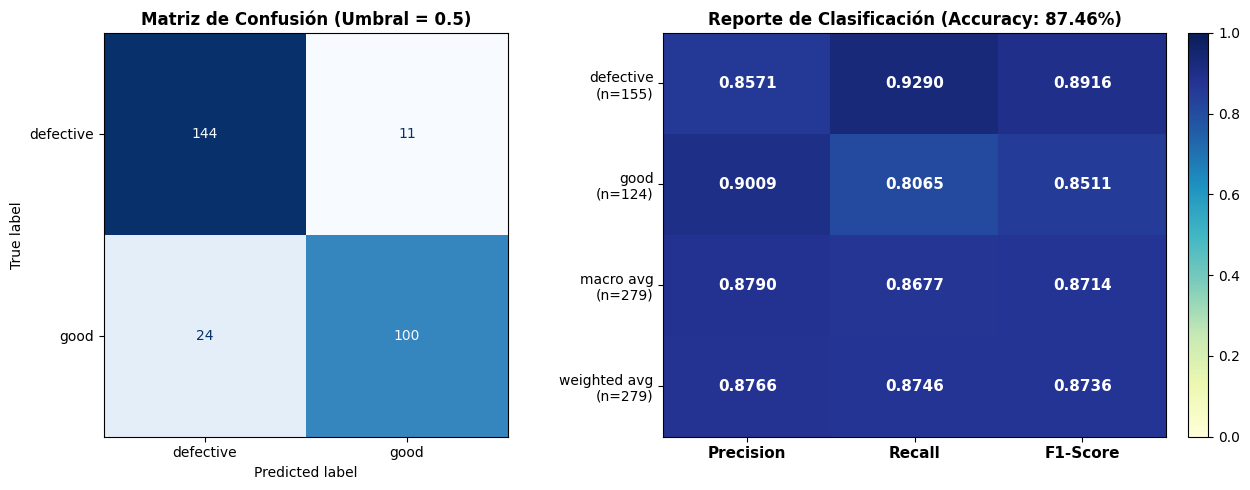

In [17]:
import pandas as pd

# Umbral de decisión (0.50 estándar; puedes subirlo a 0.65 para mayor seguridad vial)
UMBRAL = 0.50
y_pred = (y_prob >= UMBRAL).astype(int)

# 1. Convertir el reporte de clasificación a DataFrame
reporte_dict = classification_report(
    y_true, y_pred, target_names=class_names, output_dict=True
)
df_reporte = pd.DataFrame(reporte_dict).T

# Filtrar filas principales y columnas de métricas (excluyendo support para el mapa de calor)
filas_interes = class_names + ["macro avg", "weighted avg"]
df_metricas = df_reporte.loc[filas_interes, ["precision", "recall", "f1-score"]]
soportes = df_reporte.loc[filas_interes, "support"].astype(int)

# 2. Crear figura con 2 paneles: Matriz de Confusión + Reporte Visual
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Panel izquierdo: Matriz de Confusión
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(cmap="Blues", ax=ax1, values_format="d", colorbar=False)
ax1.set_title(f"Matriz de Confusión (Umbral = {UMBRAL})", fontsize=12, fontweight="bold")

# Panel derecho: Heatmap del Reporte de Clasificación
im = ax2.imshow(df_metricas.values, cmap="YlGnBu", vmin=0.0, vmax=1.0, aspect="auto")
ax2.set_xticks(np.arange(len(df_metricas.columns)))
ax2.set_xticklabels(["Precision", "Recall", "F1-Score"], fontsize=11, fontweight="bold")

# Mostrar nombre de clase + cantidad de muestras (support) en el eje Y
etiquetas_y = [f"{idx}\n(n={sup})" for idx, sup in zip(df_metricas.index, soportes)]
ax2.set_yticks(np.arange(len(df_metricas.index)))
ax2.set_yticklabels(etiquetas_y, fontsize=10)

# Escribir los valores exactos dentro de cada celda
for i in range(df_metricas.shape[0]):
    for j in range(df_metricas.shape[1]):
        valor = df_metricas.iloc[i, j]
        color_texto = "white" if valor > 0.65 else "black"
        ax2.text(
            j, i, f"{valor:.4f}",
            ha="center", va="center", color=color_texto, fontsize=11, fontweight="bold"
        )

acc_global = reporte_dict["accuracy"]
ax2.set_title(f"Reporte de Clasificación (Accuracy: {acc_global:.2%})", fontsize=12, fontweight="bold")
plt.colorbar(im, ax=ax2, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

Total de errores en Test: 35 de 279 imágenes
  - Llantas DEFECTUOSAS aprobadas como GOOD (Riesgo crítico): 11
  - Llantas GOOD rechazadas como DEFECTIVE (Falsa alarma): 24



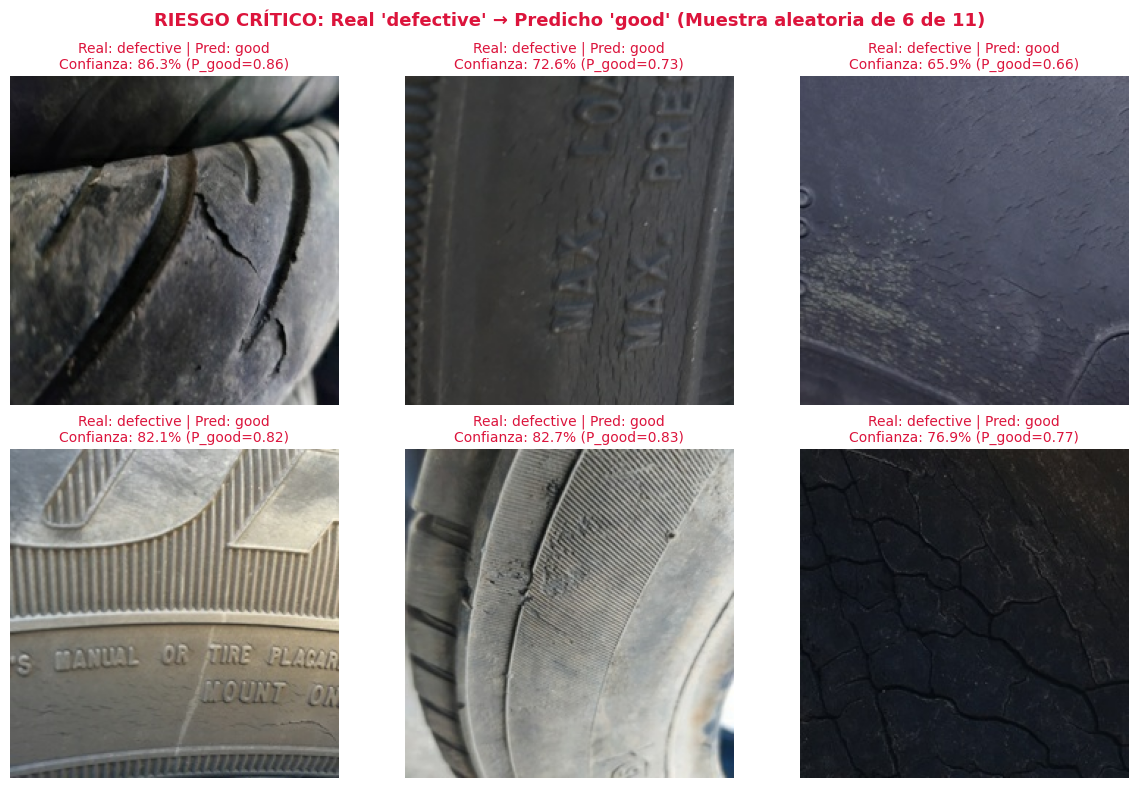

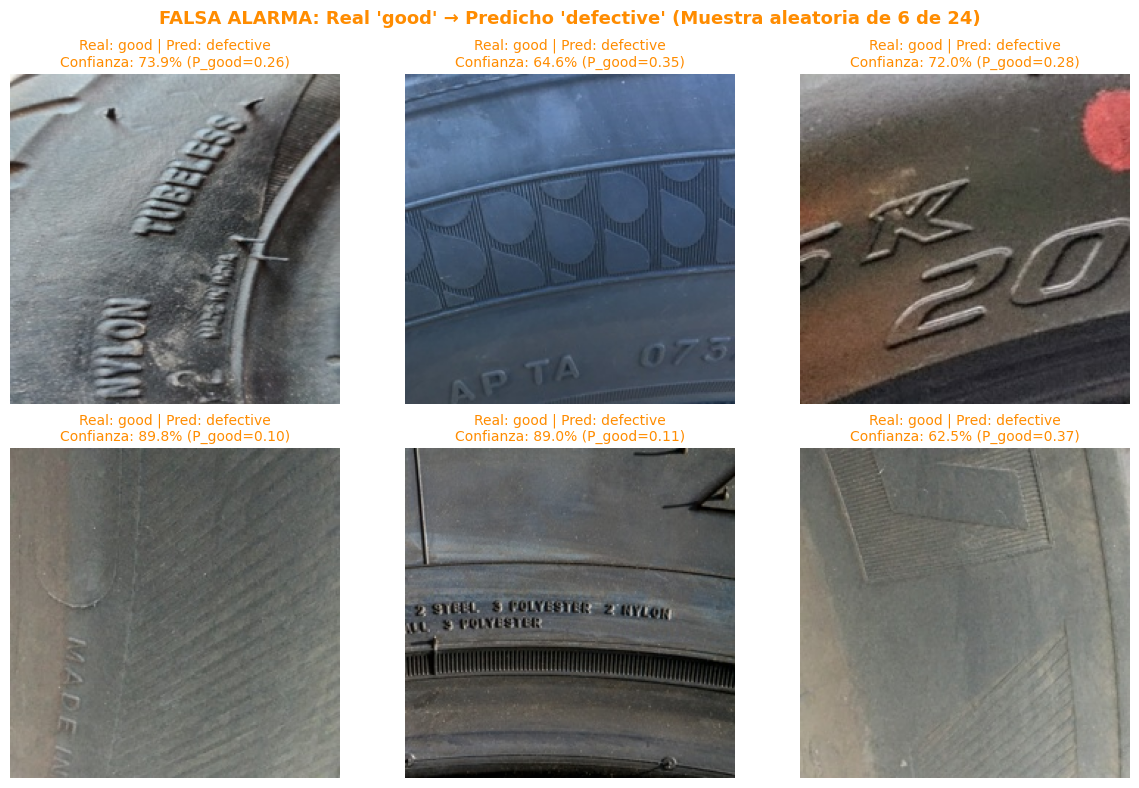

In [26]:
# Generador aleatorio (si quieres fijar una semilla reproducible, pasa un número como seed=42)
rng = np.random.default_rng()

# Separar índices por tipo de error (0 = 'defective', 1 = 'good')
# Tipo A: Realmente 'defective' (0), pero el modelo predijo 'good' (1) -> Riesgo vial
err_defective_como_good = np.where((y_true == 0) & (y_pred == 1))[0]

# Tipo B: Realmente 'good' (1), pero el modelo predijo 'defective' (0) -> Falso Negativo de clase 1
err_good_como_defective = np.where((y_true == 1) & (y_pred == 0))[0]

print(f"Total de errores en Test: {len(err_defective_como_good) + len(err_good_como_defective)} de {len(y_true)} imágenes")
print(f"  - Llantas DEFECTUOSAS aprobadas como GOOD (Riesgo crítico): {len(err_defective_como_good)}")
print(f"  - Llantas GOOD rechazadas como DEFECTIVE (Falsa alarma): {len(err_good_como_defective)}\n")


def graficar_grupo_errores(indices, titulo_grupo, color_titulo, max_imgs=6):
    if len(indices) == 0:
        print(f"Sin errores en la categoría: {titulo_grupo}")
        return

    n_mostrar = min(len(indices), max_imgs)
    # Seleccionar índices aleatorios sin reemplazo
    indices_muestra = rng.choice(indices, size=n_mostrar, replace=False)

    cols = 3
    filas = (n_mostrar + cols - 1) // cols

    fig, axes = plt.subplots(filas, cols, figsize=(12, 4 * filas))
    axes = np.atleast_1d(axes).flatten()
    fig.suptitle(
        f"{titulo_grupo} (Muestra aleatoria de {n_mostrar} de {len(indices)})",
        fontsize=13,
        fontweight="bold",
        color=color_titulo
    )

    for i, idx in enumerate(indices_muestra):
        img = imagenes_test[idx].astype("uint8")
        real = class_names[y_true[idx]]
        predicho = class_names[y_pred[idx]]
        prob_good = y_prob[idx]
        confianza = prob_good if y_pred[idx] == 1 else (1.0 - prob_good)

        axes[i].imshow(img)
        axes[i].set_title(
            f"Real: {real} | Pred: {predicho}\nConfianza: {confianza:.1%} (P_good={prob_good:.2f})",
            color=color_titulo,
            fontsize=10
        )
        axes[i].axis("off")

    for j in range(n_mostrar, len(axes)):
        axes[j].axis("off")

    plt.tight_layout()
    plt.show()


# 1. Visualizar muestra aleatoria de llantas defectuosas aprobadas como buenas
graficar_grupo_errores(
    err_defective_como_good,
    titulo_grupo="RIESGO CRÍTICO: Real 'defective' → Predicho 'good'",
    color_titulo="crimson"
)

# 2. Visualizar muestra aleatoria de llantas buenas rechazadas como defectuosas
graficar_grupo_errores(
    err_good_como_defective,
    titulo_grupo="FALSA ALARMA: Real 'good' → Predicho 'defective'",
    color_titulo="darkorange"
)

## Visualización de la curva Precision

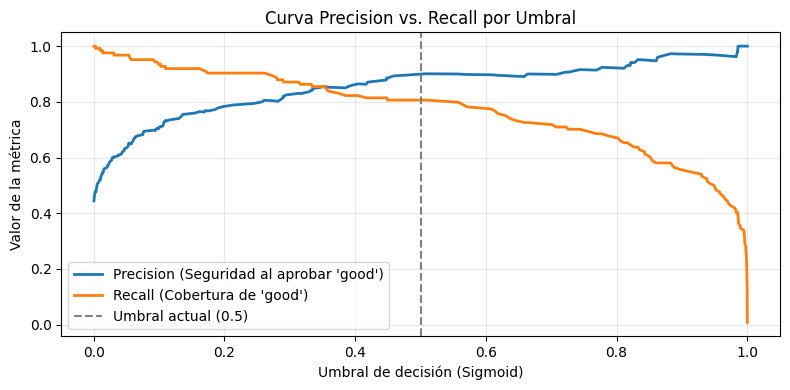

In [19]:
precisions, recalls, thresholds = precision_recall_curve(y_true, y_prob)

plt.figure(figsize=(8, 4))
plt.plot(thresholds, precisions[:-1], label="Precision (Seguridad al aprobar 'good')", linewidth=2)
plt.plot(thresholds, recalls[:-1], label="Recall (Cobertura de 'good')", linewidth=2)
plt.axvline(UMBRAL, color="gray", linestyle="--", label=f"Umbral actual ({UMBRAL})")
plt.xlabel("Umbral de decisión (Sigmoid)")
plt.ylabel("Valor de la métrica")
plt.title("Curva Precision vs. Recall por Umbral")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()